# Подготовка данных и базовая модель регрессии

Первая практическая часть диплома «Прогнозирование непрерывной величины с использованием градиентного бустинга (XGBoost, LightGBM, CatBoost) и исследование влияния числа деревьев и глубины на переобучение».

**Статус:** начальный эксперимент. Здесь подготовлены данные и разбиение выборки, выполнен EDA и рассчитана базовая линейная регрессия. XGBoost, LightGBM и CatBoost ещё не обучались. Выводов об их качестве и переобучении пока нет.

Для стартового эксперимента выбран [UCI Concrete Compressive Strength](https://archive.ics.uci.edu/dataset/165/concrete+compressive+strength): 1 030 измерений, 8 числовых признаков, целевая величина — прочность бетона в МПа. Это рабочий датасет для исследования, его можно пересмотреть при согласовании методики диплома.

In [1]:
from pathlib import Path
import json
import hashlib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import sklearn
from IPython.display import display
from sklearn.model_selection import GroupShuffleSplit
from sklearn.dummy import DummyRegressor
from sklearn.linear_model import LinearRegression
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import mean_absolute_error, root_mean_squared_error, r2_score

ROOT = Path.cwd()
REPORTS = ROOT / 'reports'
FIGURES = REPORTS / 'figures'
FIGURES.mkdir(parents=True, exist_ok=True)
plt.rcParams.update({'font.family': 'DejaVu Sans', 'font.size': 10,
                     'figure.dpi': 120, 'axes.spines.top': False, 'axes.spines.right': False})
pd.set_option('display.max_columns', 12)
data_path = ROOT / 'data/concrete.csv'
source = json.loads((ROOT / 'data/source.json').read_text(encoding='utf-8'))
assert hashlib.sha256(data_path.read_bytes()).hexdigest() == source['csv_sha256']
data = pd.read_csv(data_path)
features = ['cement', 'slag', 'fly_ash', 'water', 'superplasticizer',
            'coarse_aggregate', 'fine_aggregate', 'age_days']
target = 'strength_mpa'
print('Размер исходной таблицы:', data.shape)
print('scikit-learn:', sklearn.__version__)

Размер исходной таблицы: (1030, 9)
scikit-learn: 1.6.1


## 1. Проверка и очистка

Первые семь признаков — количество компонентов в кг/м³, `age_days` — возраст образца в днях. `strength_mpa` — измеренная прочность при сжатии. Нули у шлака, золы и пластификатора допустимы: компонент мог не добавляться.

На всей таблице проверяю только структуру и очевидные проблемы данных, не подбирая модель по тестовым значениям. Полные дубликаты удаляю до разбиения: иначе одна и та же запись могла бы попасть в обучение и проверку. Это допущение, потому что идентификатора лабораторного испытания нет; повторяющиеся строки могут быть повторными измерениями.

In [2]:
raw_rows = len(data)
duplicate_count = int(data.duplicated().sum())
assert data.columns.tolist() == features + [target]
assert not data.isna().any().any()
assert np.isfinite(data.to_numpy()).all()
assert (data[features] >= 0).all().all()
assert (data.age_days > 0).all() and (data[target] > 0).all()
data = data.drop_duplicates().copy()
data.index.name = 'row_id'  # номер строки исходного CSV, начиная с нуля
print('Полных дубликатов:', duplicate_count)
print('Строк после очистки:', len(data))

Полных дубликатов: 25
Строк после очистки: 1005


## 2. Фиксированное разбиение

Один и тот же состав смеси может встречаться в разных возрастах. Поэтому обычное случайное разбиение строк может дать слишком оптимистичную проверку на уже знакомых составах. Объединяю строки с **одинаковыми значениями семи компонентов** в группы и разделяю группы: около 60% на обучение, 20% на валидацию, 20% на тест. Доли относятся к группам; число строк может распределиться иначе.

Валидация нужна для текущей проверки базовой модели и будущего выбора параметров. Тест откладываю до конца исследования: сейчас на нём не считаю ни предсказания, ни метрики. Из-за отсутствия идентификатора эксперимента группировка приблизительная; близкие, но не идентичные составы могут оказаться по разные стороны разбиения.

In [3]:
recipe_columns = features[:-1]  # возраст не является частью рецептуры
groups = data.groupby(recipe_columns, sort=True).ngroup()
outer = GroupShuffleSplit(n_splits=1, test_size=0.2, random_state=42)
development_pos, test_pos = next(outer.split(data, groups=groups))
development = data.iloc[development_pos]
inner = GroupShuffleSplit(n_splits=1, test_size=0.25, random_state=43)
train_pos, valid_pos = next(inner.split(development, groups=groups.iloc[development_pos]))
train = development.iloc[train_pos]
valid = development.iloc[valid_pos]
test_ids = data.iloc[test_pos].index

split = pd.Series('test', index=data.index, name='split')
split.loc[train.index] = 'train'
split.loc[valid.index] = 'validation'
split_table = pd.DataFrame({'split': split, 'recipe_group': groups})
split_table.to_csv(REPORTS / 'split_assignment.csv')
assert split_table.groupby('recipe_group').split.nunique().max() == 1
assert set(train.index).isdisjoint(valid.index)
assert set(train.index).isdisjoint(test_ids)
assert set(valid.index).isdisjoint(test_ids)
split_summary = split_table.groupby('split').agg(rows=('split', 'size'), groups=('recipe_group', 'nunique'))
display(split_summary)
X_train, y_train = train[features], train[target]
X_valid, y_valid = valid[features], valid[target]

,rows,groups
split,,
test,195,86
train,623,256
validation,187,86


## 3. Исследовательский анализ только обучающей части

Чтобы не подстраивать решения под проверочные данные, распределение целевой величины и связи признаков рассматриваю на train. Большие или маленькие корректные значения не удаляю автоматически как выбросы.

,cement,slag,fly_ash,water,superplasticizer,coarse_aggregate,fine_aggregate,age_days,strength_mpa
count,623.00,623.00,623.00,623.00,623.00,623.00,623.00,623.00,623.00
mean,285.43,74.07,50.09,182.87,5.56,973.54,771.42,44.28,35.22
std,103.45,87.09,63.69,19.75,5.91,74.76,78.93,61.87,16.26
min,108.30,0.00,0.00,126.60,0.00,801.00,594.00,1.00,2.33
25%,198.60,0.00,0.00,168.94,0.00,932.00,723.15,7.00,23.58
50%,284.00,19.00,0.00,185.70,5.33,968.00,777.80,28.00,33.72
75%,349.00,142.90,107.00,192.00,9.52,1023.15,824.50,56.00,44.52
max,540.00,342.10,195.00,228.00,32.20,1130.00,992.60,365.00,81.75


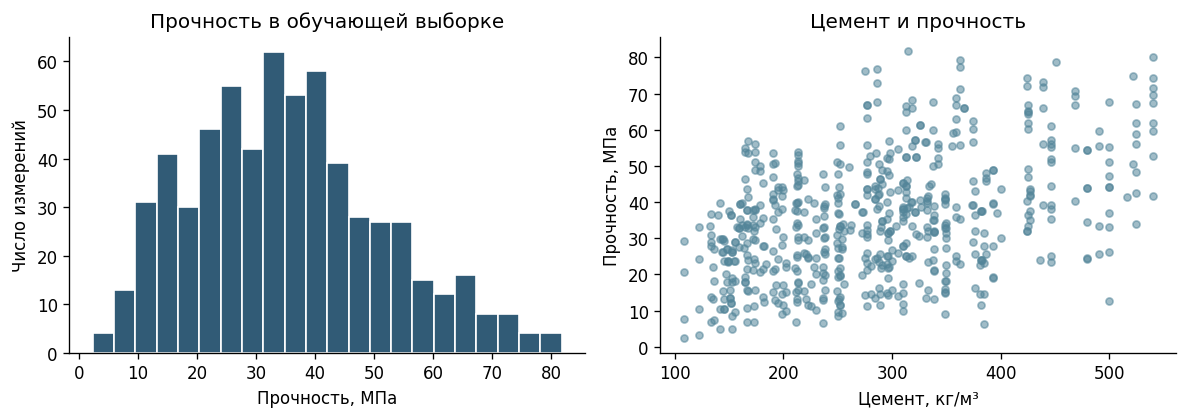

water              -0.315
fine_aggregate     -0.168
coarse_aggregate   -0.135
fly_ash            -0.050
slag                0.108
age_days            0.354
superplasticizer    0.361
cement              0.448
Name: pearson_r, dtype: float64

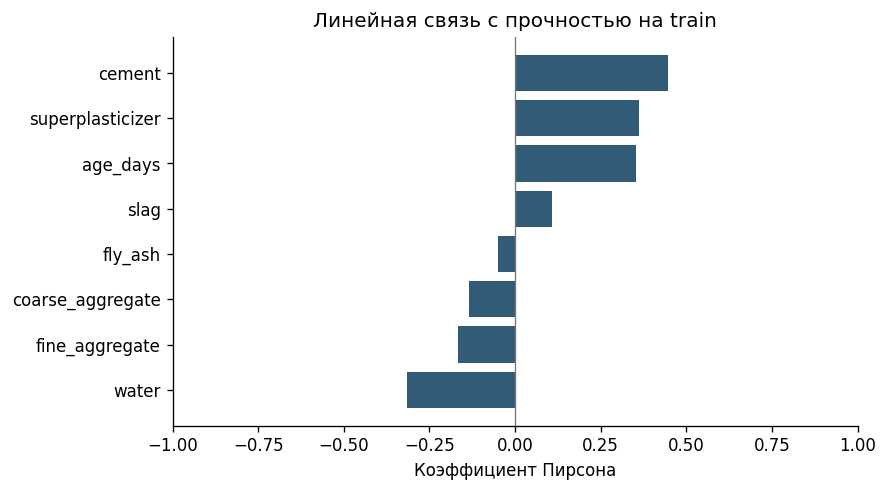

In [4]:
display(train.describe().round(2))
train.describe().to_csv(REPORTS / 'train_descriptive_stats.csv')
fig, axes = plt.subplots(1, 2, figsize=(10, 3.6))
axes[0].hist(y_train, bins=22, color='#315b76', edgecolor='white')
axes[0].set(title='Прочность в обучающей выборке', xlabel='Прочность, МПа', ylabel='Число измерений')
axes[1].scatter(train.cement, y_train, s=18, alpha=.55, color='#538599')
axes[1].set(title='Цемент и прочность', xlabel='Цемент, кг/м³', ylabel='Прочность, МПа')
fig.tight_layout()
fig.savefig(FIGURES / 'train_eda.png', bbox_inches='tight')
plt.show()

correlations = train[features + [target]].corr()[target].drop(target).sort_values()
display(correlations.rename('pearson_r').round(3))
correlations.to_csv(REPORTS / 'train_correlations.csv')
fig, ax = plt.subplots(figsize=(7.5, 4.2))
ax.barh(correlations.index, correlations, color='#315b76')
ax.axvline(0, color='#777777', linewidth=.8)
ax.set(xlim=(-1, 1), xlabel='Коэффициент Пирсона', title='Линейная связь с прочностью на train')
fig.tight_layout()
fig.savefig(FIGURES / 'train_correlations.png', bbox_inches='tight')
plt.show()

Корреляция показывает линейную связь одного признака с целевой величиной. Она не доказывает причинность и не заменяет оценку модели. Слабая корреляция также не означает бесполезность признака: зависимость может быть нелинейной или проявляться вместе с другими компонентами.

## 4. Две базовые модели

1. `DummyRegressor` всегда предсказывает среднюю прочность **обучающей выборки**. Это простой ориентир.
2. `LinearRegression` использует восемь исходных признаков без взаимодействий и полиномиальных преобразований. Масштабирование находится внутри `Pipeline` и обучается только на train. Для обычной линейной регрессии масштабирование не является обязательным, но задаёт единый способ подготовки числовых признаков.

Считаю **MAE** — среднюю абсолютную ошибку в МПа; **RMSE** — ошибку в МПа, сильнее реагирующую на большие промахи; **R²** — безразмерную оценку, которая может быть отрицательной. Главная метрика для будущего сравнения — RMSE. Никаких параметров по validation сейчас не подбираю.

In [5]:
models = {
    'Mean baseline': DummyRegressor(strategy='mean'),
    'Linear regression': make_pipeline(StandardScaler(), LinearRegression()),
}
rows = []
valid_predictions = pd.DataFrame({'actual_mpa': y_valid})
for name, model in models.items():
    model.fit(X_train, y_train)
    for split_name, X, y in [('train', X_train, y_train), ('validation', X_valid, y_valid)]:
        prediction = model.predict(X)
        rows.append({'model': name, 'split': split_name,
                     'mae_mpa': mean_absolute_error(y, prediction),
                     'rmse_mpa': root_mean_squared_error(y, prediction),
                     'r2': r2_score(y, prediction)})
        if split_name == 'validation':
            valid_predictions[name] = prediction
metrics = pd.DataFrame(rows)
display(metrics.round(3))
metrics.to_csv(REPORTS / 'baseline_metrics.csv', index=False)
valid_predictions.to_csv(REPORTS / 'validation_predictions.csv')

mean_model = models['Mean baseline']
linear_model = models['Linear regression']
assert np.isclose(mean_model.constant_.item(), y_train.mean())
np.testing.assert_allclose(linear_model.named_steps['standardscaler'].mean_, X_train.mean())
assert np.isfinite(metrics[['mae_mpa', 'rmse_mpa', 'r2']]).all().all()
print('Тестовые предсказания не рассчитывались.')

,model,split,mae_mpa,rmse_mpa,r2
0,Mean baseline,train,13.088,16.251,0.000
1,Mean baseline,validation,13.599,16.485,-0.001
2,Linear regression,train,8.170,10.275,0.600
3,Linear regression,validation,8.885,11.002,0.554


Тестовые предсказания не рассчитывались.


## 5. Ошибки линейной модели на валидации

Предсказания не округляю и не обрезаю снизу: изменение прогноза повлияло бы на метрики. Остаток ниже — фактическая прочность минус предсказанная. Если ошибки зависят от величины прогноза, простой линейной зависимости может быть недостаточно.

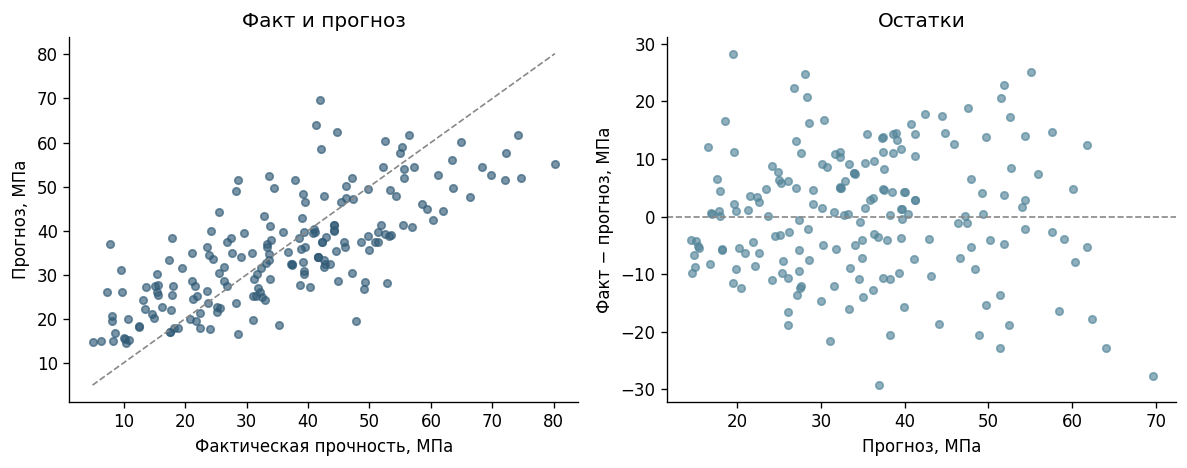

Отрицательных прогнозов на validation: 0
Снижение RMSE относительно среднего на validation: 33.3%


449

In [6]:
prediction = valid_predictions['Linear regression']
residual = y_valid - prediction
fig, axes = plt.subplots(1, 2, figsize=(10, 4))
axes[0].scatter(y_valid, prediction, s=20, alpha=.65, color='#315b76')
low = min(y_valid.min(), prediction.min())
high = max(y_valid.max(), prediction.max())
axes[0].plot([low, high], [low, high], '--', color='#888888', linewidth=1)
axes[0].set(title='Факт и прогноз', xlabel='Фактическая прочность, МПа', ylabel='Прогноз, МПа')
axes[1].scatter(prediction, residual, s=20, alpha=.65, color='#538599')
axes[1].axhline(0, linestyle='--', color='#888888', linewidth=1)
axes[1].set(title='Остатки', xlabel='Прогноз, МПа', ylabel='Факт − прогноз, МПа')
fig.tight_layout()
fig.savefig(FIGURES / 'validation_errors.png', bbox_inches='tight')
plt.show()
print('Отрицательных прогнозов на validation:', int((prediction < 0).sum()))

validation_metrics = metrics[metrics.split.eq('validation')].set_index('model')
relative_improvement = (1 - validation_metrics.loc['Linear regression', 'rmse_mpa']
                        / validation_metrics.loc['Mean baseline', 'rmse_mpa']) * 100
print(f'Снижение RMSE относительно среднего на validation: {relative_improvement:.1f}%')
summary = {
    'status': 'Initial data study and baseline only; boosting experiments not started',
    'raw_rows': raw_rows, 'duplicates_removed': duplicate_count, 'clean_rows': len(data),
    'split_rows': split_summary.rows.to_dict(), 'split_groups': split_summary.groups.to_dict(),
    'rmse_improvement_pct': relative_improvement, 'test_evaluated': False,
    'sklearn_version': sklearn.__version__, 'pandas_version': pd.__version__,
}
(REPORTS / 'summary.json').write_text(json.dumps(summary, ensure_ascii=False, indent=2), encoding='utf-8')

## 6. Что сделано и что дальше

На этом этапе есть очищенная таблица, фиксированное разбиение без пересечения одинаковых рецептур, EDA обучающей части и метрики двух простых моделей на train и validation. Это отправная точка для последующего исследования, а не результат диплома целиком.

**Следующие шаги:**

- Обучить XGBoost, LightGBM и CatBoost на том же разбиении.
- Зафиксировать learning rate и менять число деревьев и максимальную глубину. Сохранять ошибки train и validation и время обучения.
- Построить кривые ошибок. Снижение ошибки train при росте ошибки validation будет свидетельством переобучения в конкретном эксперименте; один разрыв метрик сам по себе недостаточен.
- Проверить устойчивость выводов на нескольких групповых разбиениях обучающей части. Отложенный тест оставить закрытым для выбора параметров.
- После выбора методики и модели один раз оценить её на тесте.

Одинаковая глубина у разных реализаций бустинга не означает одинаковую сложность деревьев. Это нужно учитывать при формулировке сравнения. Черновой план будущих экспериментов находится в `PLAN.md`; запусков бустинга и их результатов в текущей версии нет.